# 01 · Simulation audit

> **Independent educational simulation. Not an airline system or an approved maintenance, airworthiness or dispatch tool.** Falcon Hub Airways is fictional; every airline number below is SIMULATED by this repo's code. Provenance tags: **REAL** (public data), **DERIVED** (computed by code), **ASSUMED** (a config planning assumption), **SIMULATED** (simulator output).

**Why this notebook exists.** Every later result (forecasts, policies, the capital frontier) is only as credible as the simulated world it runs on. Before trusting any of it, a hiring manager (or a sceptical planner) should be able to check four things:

1. the fleet and its flying look like a plausible hub-and-spoke operation;
2. parts fail at rates consistent with, but not identical to, what vendors quote (the gap is the point);
3. the legacy policy P0 lands inside the calibration bands that were fixed *before* any modelling;
4. the books balance: stock, serials, requests and AOG hours are conserved;
5. the four *planted situations* (PS1–PS4) are really in the data for a planner to find.

Everything here reads the public history only (`data/processed/history`, weeks 0–103, policy P0) plus the calibration summary. No hidden truth table is opened.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))            # notebooks/_style.py
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt
from _style import *                            # palette, ROOT, stamp(), aed_m(), load_json()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("project root:", ROOT)
con = duckdb.connect(str(ROOT / "data" / "processed" / "grounded.duckdb"), read_only=True)
q = lambda sql: con.execute(sql).df()
print(q("select count(*) as views from information_schema.tables").views[0], "history views available")

project root: /Users/akashgajjar/grounded-no-more
17 history views available


## 1. Fleet and exposure

Forty fictional tails fly AUH-hub rotations to six outstations. Exposure (flight hours FH and cycles FC) is what drives removals, so it is the first thing to sanity-check: narrowbodies should fly shorter sectors (more cycles per hour), widebodies longer ones.

,archetype,tails,fh_per_tail_day,fc_per_tail_day,hours_per_cycle
0,narrowbody,24,10.55,4.24,2.49
1,widebody,16,14.50,2.44,5.95


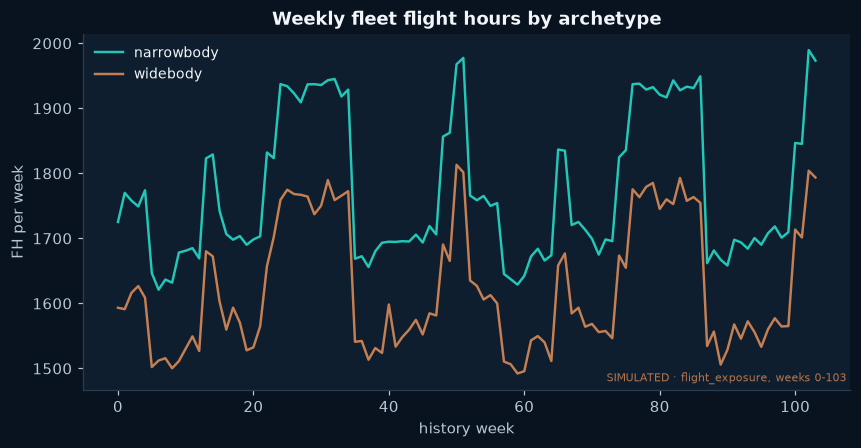

In [2]:
fleet = q("""
select am.archetype, count(distinct am.tail) as tails,
       sum(fe.fh) / count(distinct am.tail) / (104*7) as fh_per_tail_day,
       sum(fe.fc) / count(distinct am.tail) / (104*7) as fc_per_tail_day,
       sum(fe.fh) / sum(fe.fc) as hours_per_cycle
from flight_exposure fe join aircraft_master am using (tail)
group by 1 order by 1""")
display(fleet.round(2))
weekly = q("""select fe.week, am.archetype, sum(fe.fh) as fh
              from flight_exposure fe join aircraft_master am using (tail) group by all order by 1""")
w = weekly.pivot(index="week", columns="archetype", values="fh")
fig, ax = plt.subplots()
ax.plot(w.index, w["narrowbody"], color=TEAL, lw=1.6, label="narrowbody")
ax.plot(w.index, w["widebody"], color=COPPER, lw=1.6, label="widebody")
ax.set(title="Weekly fleet flight hours by archetype", xlabel="history week", ylabel="FH per week")
ax.legend(frameon=False); stamp(ax, "flight_exposure, weeks 0-103"); plt.show()

The realised utilisation (about 10.5 FH and 4.2 FC per narrowbody day, 14.5 FH and 2.4 FC per widebody day; see `docs/agent_notes/sim-engine.md`) is in the range of a typical hub carrier. The weekly series shows the configured seasonality. Station traffic is set by the route mix:

In [3]:
arr = q("""select arr_station as station, count(*) as arrivals, round(sum(fh)) as fh
           from flight_exposure group by 1 order by arrivals desc""")
display(arr)

,station,arrivals,fh
0,AUH,51255,176582.0
1,BOM,15082,37318.0
2,JED,13098,26720.0
3,CAI,11049,33257.0
4,SIN,4340,30814.0
5,LHR,4215,28072.0
6,FRA,3489,20480.0


## 2. Removal rates against the vendor quote

For every rotable (R) and expendable (E) we compare the removals the fleet actually saw with the removals the vendor-quoted MTBUR would predict for the same exposure. A ratio above 1 means the part fails more often than quoted. The simulator deliberately makes quotes noisy and, on average, optimistic. That is why the forecasting layer learns rates from data instead of trusting the master file.

75 R/E parts with removals; median actual/quoted removal ratio = 1.25
            count   25%   50%   75%
part_class                         
E            35.0  0.87  1.31  1.74
R            40.0  0.95  1.23  1.75


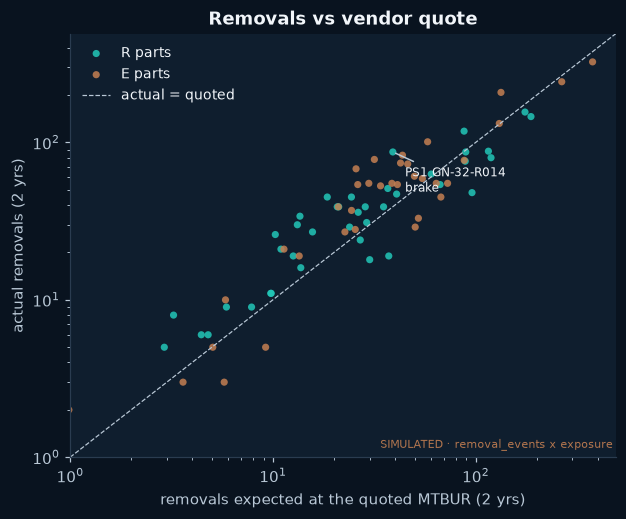

In [4]:
rates = q(open(ROOT / "sql" / "10_removal_rate_vs_quoted.sql").read().replace("LIMIT 15", "").replace(
    "WHERE r.removals >= 10", "WHERE r.removals >= 1"))
rates["expected_at_quote"] = rates.exposure / rates.mtbur_quoted
rates["actual_vs_quote"] = rates.removals / rates.expected_at_quote
print(f"{len(rates)} R/E parts with removals; median actual/quoted removal ratio = {rates.actual_vs_quote.median():.2f}")
print(rates.groupby("part_class").actual_vs_quote.describe()[["count", "25%", "50%", "75%"]].round(2))
fig, ax = plt.subplots(figsize=(6.4, 5))
for cls, col in (("R", TEAL), ("E", COPPER)):
    d = rates[rates.part_class == cls]
    ax.scatter(d.expected_at_quote, d.removals, s=22, color=col, alpha=0.85, label=f"{cls} parts", edgecolor="none")
lim = [1, rates[["expected_at_quote", "removals"]].max().max() * 1.3]
ax.plot(lim, lim, color=TITANIUM, lw=0.8, ls="--", label="actual = quoted")
ps1 = rates[rates.pn == "GN-32-R014"].iloc[0]
ax.annotate("PS1 GN-32-R014\nbrake", (ps1.expected_at_quote, ps1.removals), xytext=(8, -26),
            textcoords="offset points", color=ICE, fontsize=8, arrowprops=dict(arrowstyle="-", color=TITANIUM))
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="removals expected at the quoted MTBUR (2 yrs)",
       ylabel="actual removals (2 yrs)", title="Removals vs vendor quote")
ax.legend(frameon=False, loc="upper left"); stamp(ax, "removal_events x exposure"); plt.show()

Most points sit above the diagonal (median actual/quoted ratio about 1.25): vendor quotes are optimistic on average, but not uniformly, which is realistic. PS1, the carbon brake, fails about 2.2× as often as quoted (≈4,700 FC observed against 10,500 FC quoted). That gap is what makes the legacy policy under-stock it at outstations (section 5).

## 3. History KPIs against the calibration targets

The calibration bands (ASSUMED, in `config/assumptions.yaml: calibration_targets`) were fixed before any modelling: P0 must give 93–97 % overall immediate fill, 80–88 % rotable fill, 1,500–3,500 material AOG hours a year and 60–250 events a year. We recompute the KPIs straight from the history tables and check them against both the band and the locked calibration summary.

In [5]:
cal = load_json("outputs/calibration/p0_history_summary.json")
targets = cal["targets"]; hist = cal["variants"]["central"]["history"]
mine = q("""
select sum(case when immediate_fill then qty else 0 end) / sum(qty) as immediate_fill_rate,   -- unit-weighted
       avg(case when pm.part_class = 'R' then case when immediate_fill then 1.0 else 0.0 end end) as rotable_immediate_fill_rate,
       (select sum(hours) / 2 from aog_events) as aog_hours_per_year,
       (select count(*) / 2 from aog_events) as aog_events_per_year
from material_requests r join part_master pm using (pn)""").iloc[0]
rows = []
for k in ["immediate_fill_rate", "rotable_immediate_fill_rate", "aog_hours_per_year", "aog_events_per_year"]:
    lo, hi = targets[k]
    v = hist[k]
    rows.append(dict(kpi=k, band_lo=lo, band_hi=hi, calibration_summary=v, inside=lo <= v <= hi,
                     recomputed_here=mine.get(k, np.nan)))
kt = pd.DataFrame(rows)
display(kt.round(4))
assert kt.inside.all()
assert np.allclose(kt.recomputed_here, kt.calibration_summary, rtol=1e-9)
assert abs(kt.loc[kt.kpi == "aog_hours_per_year", "recomputed_here"].iloc[0] - hist["aog_hours_per_year"]) < 1
assert abs(kt.loc[kt.kpi == "aog_events_per_year", "recomputed_here"].iloc[0] - hist["aog_events_per_year"]) < 1e-9

,kpi,band_lo,band_hi,calibration_summary,inside,recomputed_here
0,immediate_fill_rate,0.93,0.97,0.9581,True,0.9581
1,rotable_immediate_fill_rate,0.80,0.88,0.8324,True,0.8324
2,aog_hours_per_year,1500.00,3500.00,2753.5000,True,2753.5000
3,aog_events_per_year,60.00,250.00,90.0000,True,90.0000


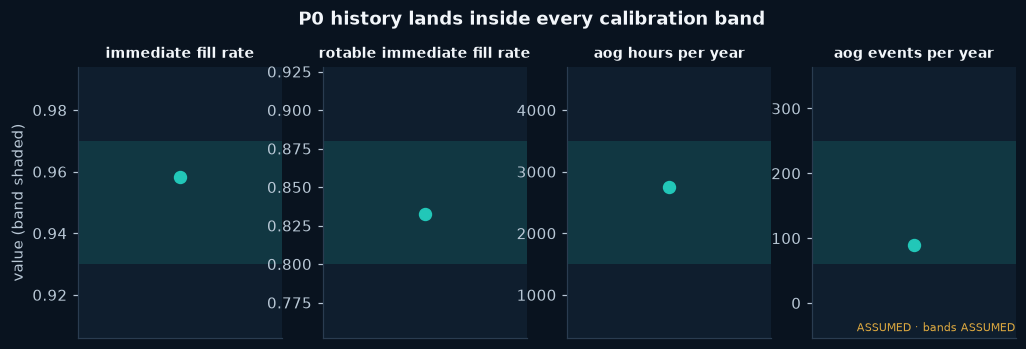

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
for ax, r in zip(axes, kt.itertuples()):
    ax.axhspan(r.band_lo, r.band_hi, color=TEAL, alpha=0.15, lw=0)
    ax.scatter([0], [r.calibration_summary], color=TEAL, s=60, zorder=3)
    pad = (r.band_hi - r.band_lo) * 0.6
    ax.set(xlim=(-1, 1), ylim=(r.band_lo - pad, r.band_hi + pad), xticks=[], title=r.kpi.replace("_", " "))
    ax.title.set_fontsize(9)
axes[0].set_ylabel("value (band shaded)")
fig.suptitle("P0 history lands inside every calibration band", color=ICE, fontweight="bold", y=1.04)
stamp(axes[-1], "bands ASSUMED", "ASSUMED"); plt.show()

All four KPIs land inside their bands, and all four recompute exactly from the history tables (overall fill is unit-weighted, rotable fill is per request, as in `gnm.sim.calibration.history_metrics`). The calibration is **locked**: `tests/test_calibration_lock.py` fails if the simulator or its config changes afterwards.

## 4. Conservation checks

A simulator that loses or invents parts would make every downstream number meaningless. These checks run directly on the history tables:

In [7]:
checks = []
def check(name, ok, detail):
    checks.append(dict(check=name, passed=bool(ok), detail=detail))

r = q("""with w as (select distinct week from stock_snapshots),
t as (select w.week, it.pn, it.station, sum(it.qty_delta) as oh
      from w join inventory_transactions it on it.t_h < (w.week + 1) * 168 group by all)
select count(*) as n, sum(case when coalesce(t.oh, 0) = s.on_hand then 1 else 0 end) as matched
from stock_snapshots s left join t using (week, pn, station)""").iloc[0]
check("on-hand = running sum of transactions (every pn x station x week)", r.n == r.matched, f"{int(r.matched):,}/{int(r.n):,} snapshot rows")

r = q("""select count(*) as bad from (select serial, since_h, lag(until_h) over (partition by serial order by since_h) prev
         from serialised_components) where prev is not null and prev <> since_h""").iloc[0]
check("serial state history is contiguous (no gaps, no overlaps)", r.bad == 0, f"{int(r.bad)} broken links")
r = q("""select count(*) as n, sum(case when k = 1 then 1 else 0 end) as ok from
         (select serial, sum(case when until_h is null then 1 else 0 end) as k from serialised_components group by 1)""").iloc[0]
check("each serial is in exactly one state at the end", r.n == r.ok, f"{int(r.ok):,}/{int(r.n):,} serials")

r = q("""select (select sum(qty) from material_requests where filled_h is not null) as filled,
                (select -sum(qty_delta) from inventory_transactions where txn_type = 'ISSUE') as issued""").iloc[0]
check("units issued = units of filled requests", r.filled == r.issued, f"{int(r.issued):,} units")

r = q("""select count(*) as n, count(ro.ro_id) as with_ro,
         (select count(*) from serialised_components where until_h is null and state = 'REMOVED') as awaiting
         from removal_events re join part_master pm using (pn) left join repair_orders ro on ro.removal_id = re.removal_id
         where pm.part_class = 'R'""").iloc[0]
check("every rotable removal has a repair order or is awaiting shipment", r.n == r.with_ro + r.awaiting,
      f"{int(r.with_ro):,} ROs + {int(r.awaiting)} awaiting = {int(r.n):,} removals")

r = q("""select (select count(*) from transfers) as shipped,
                (select count(*) from inventory_transactions where txn_type = 'TRANSFER_IN') as received,
                (select count(*) from transfers where arrive_h >= 104 * 168) as in_transit""").iloc[0]
check("transfers shipped = received + still in transit", r.shipped == r.received + r.in_transit,
      f"{int(r.shipped):,} = {int(r.received):,} + {int(r.in_transit)}")

r = q("select count(*) as n, sum(case when hours = end_h - start_h then 1 else 0 end) as ok from aog_events").iloc[0]
check("AOG event hours = end - start", r.n == r.ok, f"{int(r.ok)}/{int(r.n)} events")
ck = pd.DataFrame(checks); display(ck)
assert ck.passed.all()

,check,passed,detail
0,on-hand = running sum of transactions (every p...,True,"87,360/87,360 snapshot rows"
1,"serial state history is contiguous (no gaps, n...",True,0 broken links
2,each serial is in exactly one state at the end,True,"3,530/3,530 serials"
3,units issued = units of filled requests,True,"41,766 units"
4,every rotable removal has a repair order or is...,True,"1,738 ROs + 4 awaiting = 1,742 removals"
5,transfers shipped = received + still in transit,True,"3,059 = 3,044 + 15"
6,AOG event hours = end - start,True,180/180 events


All checks pass. The AOG Response Lab adds a stronger one: rebuilding every incident from its requests, stock checks and fills reproduces `aog_events.hours` exactly for all 180 incidents (5,507 h). That check is tested in `tests/test_aog_incidents.py`.

## 5. The planted situations

Four realistic problems were planted in the world so that a good planning process should *find* them in the history, without being told. The evidence below uses the planner SQL in `sql/`.

### PS1: carbon brakes at BOM (D0 rotable under-stocked at an outstation)

In [8]:
ps1 = q(open(ROOT / "sql" / "07_d0_outstation_no_stock.sql").read())
display(ps1[ps1.pn == "GN-32-R014"][["station", "d0_requests", "d0_without_local_stock", "aog_events", "aog_hours", "p0_base_stock"]])

,station,d0_requests,d0_without_local_stock,aog_events,aog_hours,p0_base_stock
0,BOM,16,16.0,16,144.0,0
1,CAI,10,10.0,9,99.0,0
2,JED,10,10.0,10,90.0,0
6,SIN,5,5.0,5,65.0,0
9,LHR,3,3.0,3,48.0,0
17,FRA,1,1.0,1,14.0,0


Every D0 brake request at BOM (16 in two years) found an empty shelf: P0 holds no brake at BOM, because the quoted rate is below its 4-removals-a-year threshold. Each one became an AOG event while a unit flew in from AUH (144 h in total). It is the largest outstation rotable AOG driver.

### PS2: a repair order stuck at the EU vendor

In [9]:
ro = q(open(ROOT / "sql" / "03_overdue_repair_orders.sql").read())
print(f"{len(ro)} repair orders open past their quoted due date at the end of week 103")
display(ro.head(5)[["ro_id", "pn", "shop", "removed_week", "quoted_due_week", "weeks_late", "planted"]])
tat = q("""select pn, shop, count(*) as n, avg((return_h - shop_in_h) / 24.0) as actual_shop_days,
           avg((quoted_due_h - shop_in_h) / 24.0) as quoted_shop_days
           from repair_orders where return_h is not null and not condemned and removal_id is not null and pn = 'GN-28-R031'
           group by all""")
display(tat.round(1))

33 repair orders open past their quoted due date at the end of week 103


,ro_id,pn,shop,removed_week,quoted_due_week,weeks_late,planted
0,1564,GN-28-R031,EU_VENDOR,84,93,10.3,PS2
1,1626,GN-32-R019,EU_VENDOR,87,94,9.1,
2,1577,GN-36-R010,AUH_INHOUSE,85,95,8.7,
3,1607,GN-21-R002,AUH_INHOUSE,85,95,8.7,
4,1604,GN-28-R031,EU_VENDOR,86,95,8.3,PS2


,pn,shop,n,actual_shop_days,quoted_shop_days
0,GN-28-R031,EU_VENDOR,139,89.5,64.0


RO 1564 (`GN-28-R031-S0159`, removed week 84, quoted due week 93) is still open at week 103, 10.3 weeks late. The PN's completed repairs take longer than quoted on average. A planner chasing only the master-data TAT would under-size this float.

### PS3: declining consumable demand with flat stock

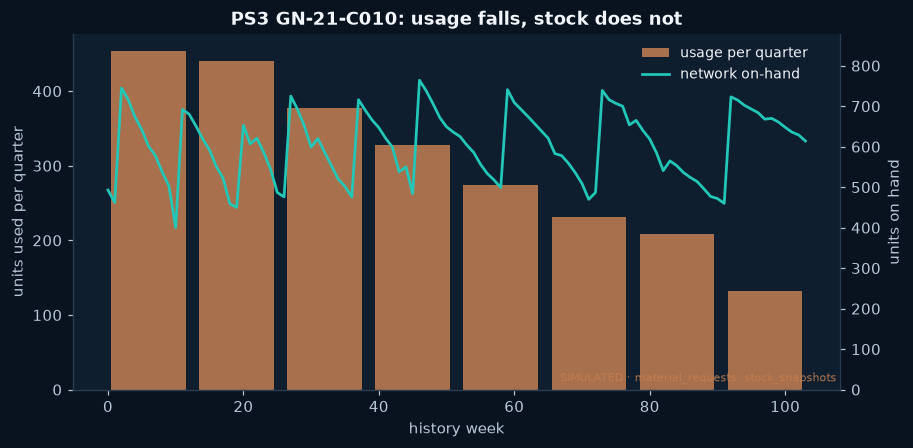

quarterly usage: [454.0, 440.0, 377.0, 328.0, 274.0, 232.0, 209.0, 132.0]


In [10]:
ps3 = q("""select week // 13 as quarter, sum(qty) as usage from material_requests where pn = 'GN-21-C010' group by 1 order by 1""")
oh = q("""select week, sum(on_hand) as on_hand from stock_snapshots where pn = 'GN-21-C010' group by 1 order by 1""")
fig, ax = plt.subplots()
ax.bar(ps3.quarter * 13 + 6, ps3.usage, width=11, color=COPPER, alpha=0.85, label="usage per quarter")
ax2 = ax.twinx(); ax2.plot(oh.week, oh.on_hand, color=TEAL, lw=1.8, label="network on-hand")
ax2.spines["right"].set_visible(True); ax2.tick_params(colors=TITANIUM)
ax.set(title="PS3 GN-21-C010: usage falls, stock does not", xlabel="history week", ylabel="units used per quarter")
ax2.set_ylabel("units on hand", color=TITANIUM); ax2.set_ylim(0, oh.on_hand.max() * 1.15)
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88), frameon=False); stamp(ax, "material_requests, stock_snapshots")
plt.show()
print("quarterly usage:", ps3.usage.tolist())

### PS4: a supplier change silently doubles a lead time

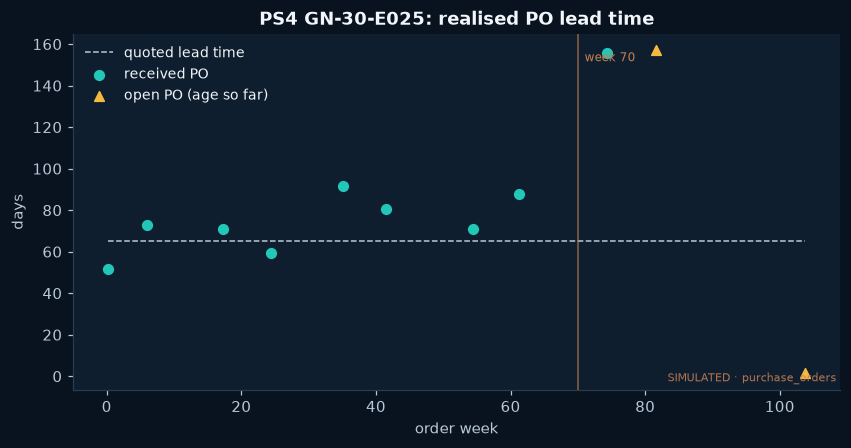

,pn,description,part_class,quoted_lead_d,earlier_pos,earlier_mean_lead_d,recent_pos,recent_open_past_due,recent_mean_lead_d,recent_vs_quoted,planted
0,GN-30-E025,Windshield wiper motor,E,65.2,7.0,71.2,3.0,1.0,133.6,2.05,PS4
1,GN-34-E023,Static port heater,E,88.4,5.0,86.1,3.0,0.0,149.6,1.69,


In [11]:
po = q("""select po_id, order_h / 168.0 as order_week, (receipt_h - order_h) / 24.0 as lead_d,
          (due_h - order_h) / 24.0 as quoted_d, receipt_h is null as open
          from purchase_orders where pn = 'GN-30-E025' and reason <> 'expedite' order by order_h""")
po["lead_d"] = po.lead_d.fillna((104 * 168 - po.order_week * 168) / 24.0)
fig, ax = plt.subplots()
ax.plot(po.order_week, po.quoted_d, color=TITANIUM, ls="--", lw=1, label="quoted lead time")
ax.scatter(po.order_week[~po.open], po.lead_d[~po.open], color=TEAL, s=40, zorder=3, label="received PO")
ax.scatter(po.order_week[po.open], po.lead_d[po.open], color=AMBER, s=40, marker="^", zorder=3, label="open PO (age so far)")
ax.axvline(70, color=COPPER, lw=1, alpha=0.7); ax.text(71, ax.get_ylim()[1] * 0.92, "week 70", color=COPPER, fontsize=8)
ax.set(title="PS4 GN-30-E025: realised PO lead time", xlabel="order week", ylabel="days")
ax.legend(frameon=False, loc="upper left"); stamp(ax, "purchase_orders"); plt.show()
display(q(open(ROOT / "sql" / "05_lead_time_drift.sql").read()))

## Summary

* The fleet, exposure and failure behaviour are plausible, and vendor quotes are optimistic in a realistic, part-specific way.
* P0 lands inside every pre-registered calibration band. The calibration is locked.
* Stock, serials, issues, repair orders, transfers and AOG hours are all conserved.
* All four planted situations are visible in the public history. A planning process can find them without access to the truth.

Next: `02_forecasting_arena.ipynb` asks how well demand can be forecast from this history.